In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('data_all.csv')
df.head()

,material,stroke,osc_freq,force,cycle,coe,Absolute Energy,Amplitude,ASL,Average Frequency,Initiation Frequency,Parametric 1,Parametric 2,Peak Frequency,Reverberation Frequency,Threshold,stage
0,steel-glass,100,10,10,1,0.023768,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
1,steel-glass,100,10,10,2,0.024692,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
2,steel-glass,100,10,10,3,0.024137,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
3,steel-glass,100,10,10,4,0.024139,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
4,steel-glass,100,10,10,5,0.023798,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 划分数据集
X = df.drop(['stage', 'material', 'stroke'], axis = 1)
y = df['stage']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y)

In [4]:
print(X_train.shape)

(16032, 14)


Epoch 1/200
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1755 - loss: 2.1357 - val_accuracy: 0.3344 - val_loss: 1.5358
Epoch 2/200
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2682 - loss: 1.7722 - val_accuracy: 0.3528 - val_loss: 1.4293
Epoch 3/200
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3195 - loss: 1.5863 - val_accuracy: 0.3756 - val_loss: 1.3554
Epoch 4/200
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3508 - loss: 1.4798 - val_accuracy: 0.3925 - val_loss: 1.3043
Epoch 5/200
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3764 - loss: 1.3914 - val_accuracy: 0.4079 - val_loss: 1.2581
Epoch 6/200
251/251 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3876 - loss: 1.3095 - val_accuracy: 0.4305 - val_loss: 1.2185
Epoch 7/200
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4099 - loss: 1.3341 - val_accuracy: 0.4419 - val_loss: 1.1939
Epoch 8/200
251/251 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4181 - loss: 1.3087 - val_accu

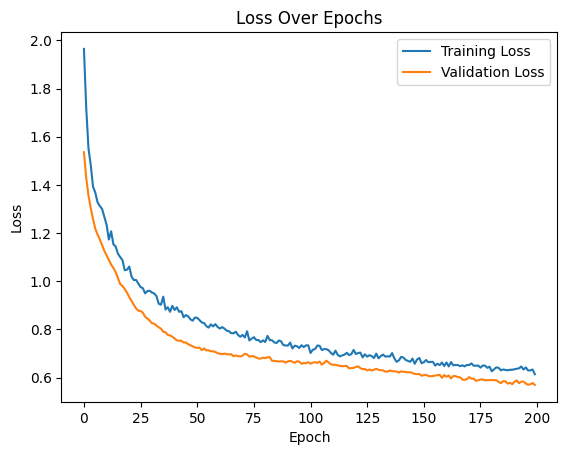

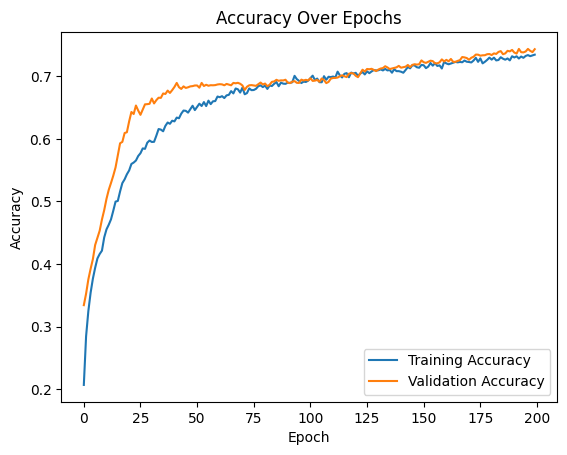

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt
from sklearn.utils import class_weight

# 计算类别权重
class_weights = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_dict = dict(enumerate(class_weights))

# 模型构建（调整后的结构）
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dense(len(np.unique(y_train)), activation='softmax')
])

# 使用自定义学习率的优化器
optimizer = Adam(learning_rate=0.00001)
model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#定义回调函数
# early_stopping = EarlyStopping(
#     monitor='val_loss',
#     patience=10,
#     restore_best_weights=True
# )
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=1e-6
)

# 训练模型
history = model.fit(
    X_train, y_train,
    epochs=200,
    batch_size=64,
    validation_data=(X_test, y_test),
    #callbacks=[early_stopping, reduce_lr],
    class_weight=class_weights_dict
)

# 绘制训练曲线
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# 绘制准确率曲线
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()